# Lab06: Introduction to Machine Learning


## 1. Machiine Learning Concepts

### 1.1 The Foundation: AI and Machine Learning 
* **Artificial Intelligence (AI):** The capability of machines to perform tasks requiring human intelligence, such as understanding language, recognizing images, and making decisions. Not all AI is machine learning (e.g., rule-based systems or typical chess engines).

* **Machine Learning (ML):** A branch of AI that enables computers to learn from data and improve performance over time without explicit programming. It identifies patterns to make predictions or decisions on new, unseen information (e.g., a spam filter).

### 1.2 Core Data and Model Concepts 
* **Data:** Information collected, analyzed, and used to make decisions. In ML, this can be numbers, text, images (pixel intensities), or any form of input.

* **Model**: A mathematical representation trained to recognize patterns in data and make predictions. It's often a mapping function between an input and an output( e.g the line equation in linear regression).

* **Model Fitting / Training / Learning**: The process of adjusting a model's internal parameters to find the best match between its predictions and the actual data.

* **Training Data:** A subset of data used to teach the model, consisting of input examples paired with their correct outputs (labels).

* **Test Data (Test Set)**: A completely separate collection of data used only to evaluate how well the trained model performs on examples it hasn't seen.



### 1.3 Machine Learning Learning Paradigms: 
* **Supervised Learning**: Models learn from labeled examples, where the correct outcomes or targets are known and provided. This is the most common type of ML (approx. 70% of applications).

* **Unsupervised Learning**: Models find patterns and structure in data without labeled examples or correct answers. It discovers natural groupings or relationships on its own (e.g., customer segmentation).

* **Reinforcement Learning**: An agent learns through interaction and feedback (trial and error), receiving rewards for good decisions and penalties for poor ones. It's powerful for sequential decision-making tasks like game playing.

![bias](images/MachineLearningVariants.png)


### 1.4 Features and Data Pre-processing
* **Feature:** A specific piece of information or characteristic used as input for a model (e.g., square footage, number of bedrooms).

* **Target (Dependent Variable / Label):** The value the model is trying to predict based on the features (e.g., the house price or 'spam'/'not spam').

* **Feature Engineering:** The process of creating new, more informative features from existing raw data to improve model performance (e.g., transforming a raw date into 'is holiday').

* **Feature Scaling / Normalization / Standardization:** Transforming numeric features to a similar scale to prevent features with larger ranges from dominating the learning process.

* **Dimensionality:** The number of features in a dataset.

### Supervised Learning: Regression vs Classification

| Category       | Description                                                      | Example                                                                                        |
| ---            | ---                                                              | ---                                                                                            |
| Regression     |	Predicting a continuous numeric target variable.                |	Predicting the price of a house or a person's weight.                                        |
| Classification |	Assigning a discrete categorical label (class) to a data point. |	Classifying an email as "spam" or "not spam," or classifying an image as a "cat" or a "dog." |

## Linear Regression

Suppose we are given a dataset of $n$ independent observations

$$
\mathcal{D} = \left\{ \left(\mathbf{x}^{(i)}, y^{(i)}\right) \right\}_{i=1}^{n},
$$

where each input $\mathbf{x}^{(i)} \in \mathbb{R}^{d}$ is a $d$-dimensional feature vector and each target $y^{(i)} \in \mathbb{R}$ is a scalar. We assume that the inputs and targets are related through an unknown function $f$, perturbed by additive noise:

$$
y = f(\mathbf{x}) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^{2}),
$$

where the noise term $\varepsilon$ is assumed to be Gaussian with zero mean and variance $\sigma^{2}$, and independent of $\mathbf{x}$.

A linear regression model approximates $f$ under the assumption that the underlying relationship between $\mathbf{x}$ and $y$ is linear. The model's prediction for the $i$-th observation is given by

$$
\hat{y}^{(i)} = \hat{f}\left(\mathbf{x}^{(i)}\right) = \mathbf{w}^{\top} \mathbf{x}^{(i)} + b,
$$

where $\mathbf{w} = (w_1, w_2, \ldots, w_d)^{\top} \in \mathbb{R}^{d}$ is the weight vector and $b \in \mathbb{R}$ is the bias (intercept) term. Expanding the inner product, this can be written equivalently as

$$
\hat{y}^{(i)} = w_1 x_1^{(i)} + w_2 x_2^{(i)} + \cdots + w_d x_d^{(i)} + b = \sum_{j=1}^{d} w_j x_j^{(i)} + b.
$$

> **Remark.** The bias term can be absorbed into the weight vector by augmenting each input with a constant feature, i.e. $\tilde{\mathbf{x}}^{(i)} = \left(1, x_1^{(i)}, \ldots, x_d^{(i)}\right)^{\top}$ and $\tilde{\mathbf{w}} = (b, w_1, \ldots, w_d)^{\top}$, so that $\hat{y}^{(i)} = \tilde{\mathbf{w}}^{\top} \tilde{\mathbf{x}}^{(i)}$.

### Training

The parameters $\mathbf{w}$ and $b$ are estimated from the data by minimizing a loss function that measures the discrepancy between the model's predictions and the observed targets. The standard choice is the mean squared error (MSE):

$$
\mathcal{L}(\mathbf{w}, b) = \frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} - \hat{y}^{(i)} \right)^{2} = \frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} - \mathbf{w}^{\top} \mathbf{x}^{(i)} - b \right)^{2}.
$$

This choice follows directly from the Gaussian noise assumption: since $y^{(i)} \mid \mathbf{x}^{(i)} \sim \mathcal{N}\left(\mathbf{w}^{\top} \mathbf{x}^{(i)} + b, \sigma^{2}\right)$, maximizing the likelihood of the observed data is equivalent to minimizing the sum of squared residuals. In other words, the least-squares estimator coincides with the maximum likelihood estimator.

Using the augmented notation from the remark above, let $\mathbf{X} \in \mathbb{R}^{n \times (d+1)}$ be the design matrix whose $i$-th row is $\left(\tilde{\mathbf{x}}^{(i)}\right)^{\top}$, and let $\mathbf{y} = \left(y^{(1)}, \ldots, y^{(n)}\right)^{\top} \in \mathbb{R}^{n}$. The loss can then be written compactly as

$$
\mathcal{L}(\tilde{\mathbf{w}}) = \frac{1}{n} \left\lVert \mathbf{y} - \mathbf{X} \tilde{\mathbf{w}} \right\rVert_2^{2}.
$$

Because this function is convex in $\tilde{\mathbf{w}}$, any stationary point is a global minimum. Setting the gradient to zero yields the **normal equations** $\mathbf{X}^{\top} \mathbf{X} \tilde{\mathbf{w}} = \mathbf{X}^{\top} \mathbf{y}$. Provided that $\mathbf{X}^{\top} \mathbf{X}$ is invertible, they have the closed-form solution

$$
\hat{\mathbf{w}} = \left( \mathbf{X}^{\top} \mathbf{X} \right)^{-1} \mathbf{X}^{\top} \mathbf{y}.
$$

Computing this solution requires solving a $(d+1) \times (d+1)$ linear system, which costs $\mathcal{O}(d^{3})$. This becomes impractical when the number of features is large. In such cases, the parameters are instead found iteratively by **gradient descent**. Starting from an initial guess, the weights are repeatedly updated in the direction of steepest descent:

$$
\tilde{\mathbf{w}}_{t+1} = \tilde{\mathbf{w}}_{t} - \eta \, \nabla \mathcal{L}(\tilde{\mathbf{w}}_{t}) = \tilde{\mathbf{w}}_{t} + \frac{2\eta}{n} \mathbf{X}^{\top} \left( \mathbf{y} - \mathbf{X} \tilde{\mathbf{w}}_{t} \right),
$$

where $\eta > 0$ is the learning rate. For very large datasets, stochastic or mini-batch variants of gradient descent are commonly used. These estimate the gradient from a random subset of the observations at each step.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

class LinearRegression:

    def __init__(self, num_features, learning_rate=0.01, n_epochs=100):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.w = np.random.randn(num_features)
        self.b = 0.0
        self.num_features = num_features

    def fit(self, X, y):

 
        for _ in range(self.n_epochs):
            for i in range(X.shape[0]):
                error = y[i] - (X[i] @ self.w + self.b)
                # Gradient of (y_i - w^T x_i - b)^2 is -2 * error * x_i
                self.w += 2 * self.learning_rate * error * X[i]
                self.b += 2 * self.learning_rate * error
 
 
        return self
    
    def predict(self, X):
        return X @ self.w + self.b


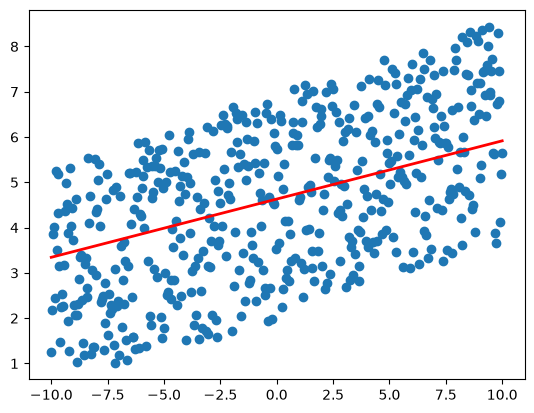

In [9]:
def create_polinomial(power=1,noise=5,upper=10,lower=-10,num_points=500):
    x = np.linspace(lower,upper,num_points)

    y= np.random.rand(1)*2 + np.random.rand(num_points)*noise
    for i in range(power):
        y += x**(i+1) * np.random.randn(1)*2
    return x,y


x,y = create_polinomial()

lr = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr.fit(x.reshape(500,1),y)
pred = lr.predict(x.reshape(500,1))
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")


## Logistic Regression

Logistic regression is a model for **binary classification**. As before, we are given $n$ independent observations $\left\{ \left(\mathbf{x}^{(i)}, y^{(i)}\right) \right\}_{i=1}^{n}$ with $\mathbf{x}^{(i)} \in \mathbb{R}^{d}$, but the targets now take values in $\{0, 1\}$. Rather than predicting $y$ directly, the model estimates the probability that an observation belongs to the positive class. It does so by passing the linear score $\mathbf{w}^{\top} \mathbf{x} + b$ through the **sigmoid** (logistic) function

$$
\sigma(z) = \frac{1}{1 + e^{-z}},
$$

which maps any real number to the interval $(0, 1)$. The model is therefore

$$
\hat{p}^{(i)} = P\left(y^{(i)} = 1 \mid \mathbf{x}^{(i)}\right) = \sigma\left(\mathbf{w}^{\top} \mathbf{x}^{(i)} + b\right).
$$


A class label is obtained by thresholding the predicted probability, typically predicting $\hat{y}^{(i)} = 1$ whenever $\hat{p}^{(i)} \geq 0.5$. Since $\sigma(z) \geq 0.5$ exactly when $z \geq 0$, the decision boundary is the hyperplane $\mathbf{w}^{\top} \mathbf{x} + b = 0$. Logistic regression is therefore a linear classifier.

### Training

In linear regression the targets were modeled with Gaussian noise. Here each target is instead modeled as a Bernoulli random variable, $y^{(i)} \mid \mathbf{x}^{(i)} \sim \operatorname{Bernoulli}\left(\hat{p}^{(i)}\right)$. Maximizing the likelihood of the data is then equivalent to minimizing the **binary cross-entropy** (log loss):

$$
\mathcal{L}(\mathbf{w}, b) = -\frac{1}{n} \sum_{i=1}^{n} \left[ y^{(i)} \log \hat{p}^{(i)} + \left(1 - y^{(i)}\right) \log\left(1 - \hat{p}^{(i)}\right) \right].
$$

This loss is convex, so any minimum is a global minimum. Unlike the least-squares problem, however, setting its gradient to zero gives no closed-form solution, so the parameters must be found iteratively. Using the augmented notation and design matrix $\mathbf{X}$ from before, the gradient takes a remarkably simple form:

$$
\nabla \mathcal{L}(\tilde{\mathbf{w}}) = \frac{1}{n} \mathbf{X}^{\top} \left( \sigma(\mathbf{X} \tilde{\mathbf{w}}) - \mathbf{y} \right),
$$

where $\sigma$ is applied element-wise. This expression is structurally identical to the linear regression gradient, with the prediction $\mathbf{X}\tilde{\mathbf{w}}$ replaced by $\sigma(\mathbf{X}\tilde{\mathbf{w}})$. As a result, the same gradient descent and stochastic gradient descent procedures apply with only this change:

$$
\tilde{\mathbf{w}}_{t+1} = \tilde{\mathbf{w}}_{t} - \frac{\eta}{n} \mathbf{X}^{\top} \left( \sigma(\mathbf{X} \tilde{\mathbf{w}}_{t}) - \mathbf{y} \right).
$$

> **Remark.** When the two classes are perfectly linearly separable, the likelihood can be increased indefinitely by scaling up $\tilde{\mathbf{w}}$. The weights then diverge instead of converging. In practice this is prevented by adding a regularization term such as $\lambda \lVert \mathbf{w} \rVert_2^{2}$ to the loss.

In [10]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, num_features, learning_rate=0.01, n_epochs=100):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.w = np.random.randn(num_features)
        self.b = 0.0

    def fit(self, X, y):
 
        for _ in range(self.n_epochs):
            # Visit the examples in a random order each epoch
            for i in range(X.shape[0]):
                p = sigmoid(X[i] @ self.w + self.b)
                error = p - y[i]
                # Gradient of the cross-entropy for one example is (p - y) * (x_i, 1)
                self.w -= self.learning_rate * error * X[i]
                self.b -= self.learning_rate * error
 
        return self

    def predict_proba(self, X):
            return sigmoid(X @ self.w + self.b)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)
    

Original classes:


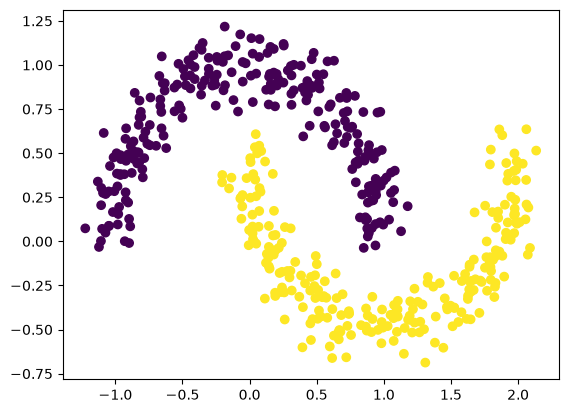

Predicted classes:


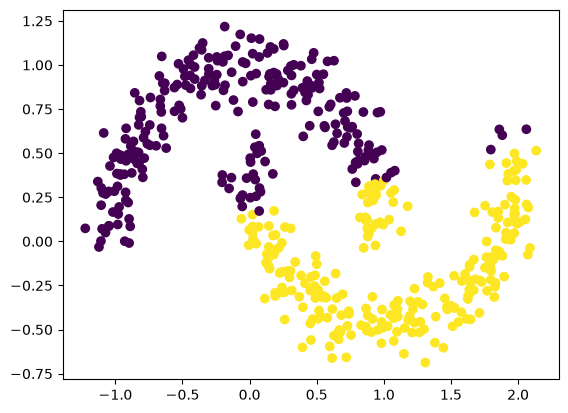

In [11]:
X, y = make_moons(n_samples=500, noise=0.1)
print("Original classes:")
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

log_reg = LogisticRegression(2,n_epochs=1000,learning_rate=0.001)
log_reg.fit(X,y)
preds = log_reg.predict(X)
print("Predicted classes:")
plt.scatter(X[:, 0], X[:, 1], c=preds)
plt.show()


## Underfitting

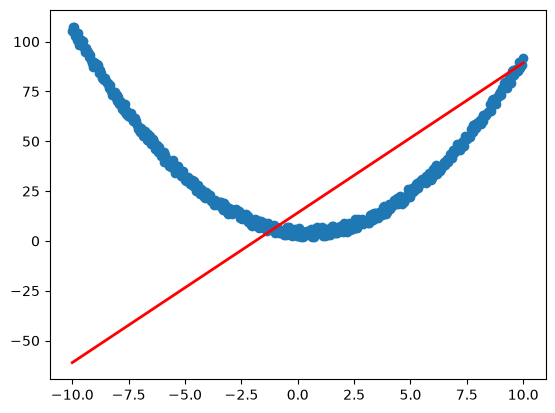

In [12]:
x,y = create_polinomial(power=2,lower=-10,upper=10)
lr = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr.fit(x.reshape(500,1),y)
pred = lr.predict(x.reshape(500,1))
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")

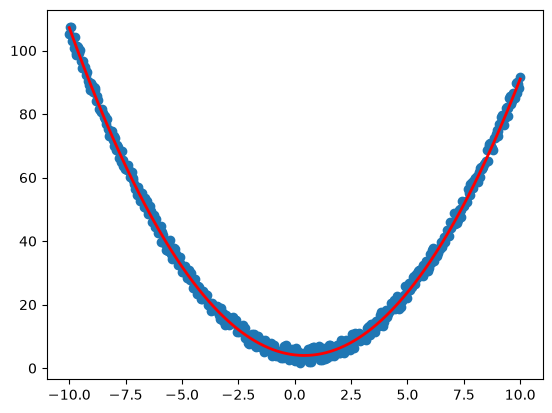

In [13]:
def engineer_features(x,power=2):
    return np.column_stack([ x**(i+1) for i in range(power)])

x_new = engineer_features(x,power=2)

lr = LinearRegression(2,n_epochs=1000,learning_rate=0.00001)
lr.fit(x_new,y)
pred = lr.predict(x_new)
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")

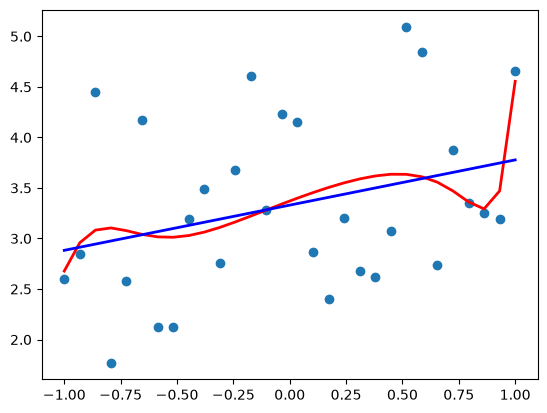

In [14]:
x,y = create_polinomial(power=1,upper=1,lower=-1,num_points=30,noise=3)

x_new = engineer_features(x,power=20)

lr = LinearRegression(20,n_epochs=1000,learning_rate=0.001)
lr.fit(x_new,y)
lr2 = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr2.fit(x.reshape(30,1),y)
pred = lr.predict(x_new)
pred2 = lr2.predict(x.reshape(30,1))

plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")
plt.plot(x, pred2, color="blue", linewidth=2, label=f"pred")


## 2. Model Performance and Trade-offs
* **Model Complexity:** How sophisticated a model is in capturing patterns, determined by the number of its parameters (e.g., number of layers in a neural network).

* **Bias** is the inability of a machine learning method to accurately capture the true underlying relationship in the data.  Bias is the error introduced by approximating a real-world problem (which may be very complex) with a much simpler model. It measures how far the average prediction of your model is from the correct value.
  
![bias](images/bias.png)

* **Variance:** How much a model's predictions would change if it were trained on different subsets of the data. High variance indicates high sensitivity to the training data.

* **Bias-Variance Trade-off:** 

*The tradeoff is that decreasing bias typically increases variance, and decreasing variance typically increases bias.*

bias = incapability to capture the underlying relationship in the data.
                
variance = sensitivity to different data; difference in model performence for different data sets                

The **ideal algorithm** must have **low bias** and **low variance**. This is achieved by finding the  sweet spot—a model complexity that is flexible enough to capture the true relationship but simple enough to produce consistent predictions across different datasets.

* **Noise:** Random variations or errors in data that don't represent true underlying patterns.

* **Overfitting:** Occurs when a model learns the random noise and fluctuations in the training data instead of the true patterns, resulting in good training performance but poor generalization. The model has high variance.

* **Underfitting:** Occurs when a model is too simple to capture the important patterns, resulting in poor performance on both training and test data. The model has *high bias*.

* Low Complexity Model => High Bias, Low Variance (Underfitting)
* High Complexity Mode => Low Bias, High Variance (Overfitting)

#### Training anf Opyimization Techniques
- Validation: Evaluating a model's performance on a held-out portion of the training data (the validation set) during the development process.

- Cross Validation: Extends validation by repeatedly training and validating the model on different, multiple splits of the data for a more robust performance estimate.

- Batch: A subset of training data processed together in a single step of training. The batch size is an important hyperparameter.

- Iteration: A single pass through one batch of data, leading to an update of the model's parameters.

- Epoch: A complete pass through the entire training data set.

- Parameter (Weight / Model Parameter): A value that the model learns from the data during training (e.g., the slope and intercept in linear regression). Finding these is the goal of training.

- Hyperparameter: A configuration setting set before training begins to control the learning process (e.g., learning rate, batch size, number of epochs).

- Learning Rate: A crucial hyperparameter that determines how much the model adjusts its parameters in response to errors.

- Cost Function (Loss/Objective Function): A measure of how wrong a model's predictions are compared to the true values. The goal of training is to minimize this function.

#### Cross Validation and dataset spliting

![bias](images/CrossValidation.png)
